In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as F
from torch.utils._pytree import tree_map
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import data_loaders
from data_loaders import commit_dataset, CommitedDataset
from dl_trainer import Trainer
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [6]:
try:
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=512, d_embed=128, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=512, d_embed=128, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [7]:
def _plot_tsne_pca_stuff(em, axem, bs, axbs):
    # weights = sklearn.decomposition.PCA(n_components=128).fit_transform(em)
    # weights = sklearn.manifold.TSNE(perplexity=10).fit_transform(weights)
    weights = sklearn.decomposition.PCA(n_components=2).fit_transform(em)
    axem.scatter(weights[:, 0], weights[:, 1], s=1)
    axbs.hist(bs, log=True)



@torch.no_grad()
def plot_tsne_pca_stuff(use_bias=True):
    global item_model, user_model
    item_model.eval(), user_model.eval()
    item_model, user_model = item_model.to('cpu'), user_model.to('cpu')
    _, axs = plt.subplots(2, 2, figsize=(8, 6))
    axs = axs.flatten()

    item_ids = data_model.ratings['item_id'].unique()
    item_feat = data_model.get_item_features(item_ids).astype(np.float32)
    iem, ibs = item_model(torch.tensor(item_ids), torch.tensor(item_feat))
    if not use_bias:
        iem, _ = item_model(torch.tensor(item_ids), torch.tensor(item_feat), use_bias=False)

    axs[0].set_title("Item Embeddings")
    _plot_tsne_pca_stuff(iem.cpu().numpy(), axs[0], ibs.cpu().numpy(), axs[2])
    del item_ids, item_feat, iem, ibs

    user_ids = data_model.ratings['user_id'].unique()
    user_feat = data_model.get_user_features(user_ids).astype(np.float32)
    uem, ubs = user_model(torch.tensor(user_ids), torch.tensor(user_feat))
    if not use_bias:
        uem, _ = user_model(torch.tensor(user_ids), torch.tensor(user_feat), use_bias=False)

    axs[1].set_title("User Embeddings")
    _plot_tsne_pca_stuff(uem.cpu().numpy(), axs[1], ubs.cpu().numpy(), axs[3])
    del user_ids, user_feat, uem, ubs

    plt.show()

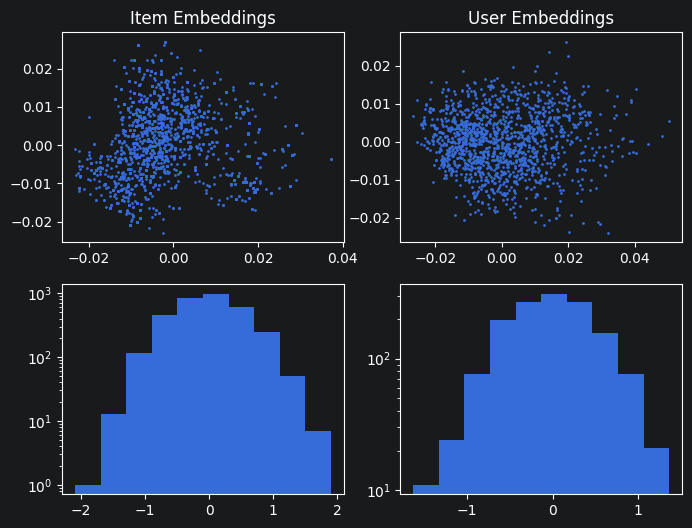

In [8]:
try:
    pass
    plot_tsne_pca_stuff(False)
except:
    traceback.print_exc()

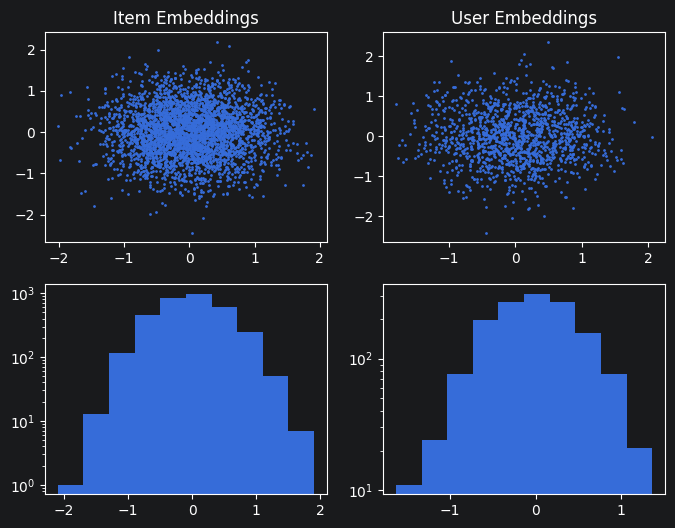

In [9]:
try:
    pass
    plot_tsne_pca_stuff(True)
except:
    traceback.print_exc()

In [10]:
class VVICDatasetIdx(Dataset):
    def __init__(self, data_model: 'DataModel', ratings=None, paravalance=6):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        # self.ratings = self.ratings.sample(frac=1)
        self.median = 0.8
        self.paravalance = paravalance

        self.user_ids = self.ratings['user_id'].to_numpy()
        self.ratings_values = self.ratings['rating'].to_numpy()

        self.user_pos_indices = {}
        self.user_neg_indices = {}

        for idx, (u, r) in enumerate(zip(self.user_ids, self.ratings_values)):
            if r >= self.median:
                if u not in self.user_pos_indices:
                    self.user_pos_indices[u] = []
                self.user_pos_indices[u].append(idx)
            else:
                if u not in self.user_neg_indices:
                    self.user_neg_indices[u] = []
                self.user_neg_indices[u].append(idx)

        for u in self.user_pos_indices:
            self.user_pos_indices[u] = np.array(self.user_pos_indices[u])
        for u in self.user_neg_indices:
            self.user_neg_indices[u] = np.array(self.user_neg_indices[u])

        self.all_indices = np.arange(len(self.ratings))

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id = self.user_ids[idx]

        pos_candidates = self.user_pos_indices[user_id]
        pos_id = pos_candidates[np.random.randint(len(pos_candidates))]

        neg_ids = np.random.choice(self.user_neg_indices[user_id], size=self.paravalance)

        return user_id, pos_id, neg_ids


class VVICDataset(Dataset):
    def __init__(self, idx_data: VVICDatasetIdx, data_model: 'DataModel'):
        self.idx_data = idx_data
        self.data_model = data_model

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.data_model.get_user_features(user_id)

        pos_item_id, pos_item_rating = self.data_model.ratings.iloc[pos_id][['item_id', 'rating']]
        pos_item_feat = self.data_model.get_item_features(pos_item_id)

        neg_item_data = []
        neg_item_ratings = []
        for neg_id in neg_ids:
            neg_item_id, neg_item_rating = data_model.ratings.iloc[neg_id][['item_id', 'rating']]
            neg_item_feat = self.data_model.get_item_features(neg_item_id)
            neg_item_data.append((neg_item_id, neg_item_feat))
            neg_item_ratings.append(neg_item_rating.astype(np.float32))

        return (
            (
                user_id, user_feat,
                pos_item_id, pos_item_feat,
                neg_item_data
            ),
            (
                pos_item_rating.astype(np.float32),
                neg_item_ratings
            )
        )


class VVICDatasetV2(Dataset):
    def __init__(self, idx_data, data_model):
        self.idx_data = idx_data
        self.data_model = data_model

        df = data_model.ratings

        self.item_ids = df['item_id'].to_numpy()
        self.ratings = df['rating'].to_numpy(dtype=np.float32)

        self.user_features = data_model.user_features.sort_index().to_numpy()
        self.item_features = data_model.item_features.sort_index().to_numpy()

    def __len__(self):
        return self.data_model.ratings.shape[0]
        # return 100

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.user_features[user_id]
        pos_item_id = self.item_ids[pos_id]
        pos_item_feat = self.item_features[pos_item_id]
        pos_rating = self.ratings[pos_id]

        neg_item_ids = self.item_ids[neg_ids]
        neg_item_feats = [self.item_features[i].astype(np.float32) for i in neg_item_ids]
        neg_ratings = tuple(self.ratings[neg_ids])

        neg_item_data = tuple(zip(neg_item_ids, neg_item_feats))

        return (
            (
                user_id, user_feat.astype(np.float32),
                pos_item_id, pos_item_feat.astype(np.float32),
                neg_item_data
            ),
            (
                pos_rating,
                # THIS DATA IS USELESS AS IT"S NOT IN THE PERSPECTIVE OF THE USER< THEREFROE WE ASSUME IT 0 ANYWAYS
                neg_ratings
            )
        )


try:
    vvic = VVICDatasetV2(VVICDatasetIdx(data_model), data_model)
    (uid, uft, pii, pif, nid), (pir, nirs) = vvic[0]
    print("User", uid.dtype, uid, uft.dtype, uft.shape)
    print("PosI", pii.dtype, pii, pif.dtype, pif.shape, pir.dtype, pir)
    for (nii, nif), nirs in zip(nid, nirs):
        print("NegI", nii.dtype, nii, nif.dtype, nif.shape, nirs.dtype, nirs)
    print("AcNI", np.mean(nirs))
except:
    traceback.print_exc()

User int64 1520 float32 (1582,)
PosI int64 8498 float32 (429,) float32 1.3409469
NegI int64 3096 float32 (429,) float32 0.65216774
NegI int64 6057 float32 (429,) float32 0.5059333
NegI int64 10051 float32 (429,) float32 0.53576297
NegI int64 1298 float32 (429,) float32 0.7777899
NegI int64 3652 float32 (429,) float32 0.66106725
NegI int64 2522 float32 (429,) float32 0.72332114
AcNI 0.72332114


In [11]:
try:
    if False:
        commit_dataset(VVICDatasetIdx(data_model), "VVICDatasetIdx", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [12]:
try:
    if False:
        vvic = VVICDataset(CommitedDataset('VVICDatasetIdx', os.path.join('..', 'temp', 'commited_datasets')), data_model)
except:
    traceback.print_exc()

In [13]:
try:
    if False:
        commit_dataset(vvic, "VVICDatasetNeg", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [14]:
try:
    if True:
        vvic = CommitedDataset('VVICDatasetNeg', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [15]:
def model_train_step(model, data):
    uid, uft, pii, pif, nid = data
    pos_score = model(uid, uft, pii, pif)[0]
    neg_scores = [model(uid, uft, nii, nif)[0] for nii, nif in nid]
    return pos_score, neg_scores


def model_criteria_step(criterion, preds, truth, weight=0.38):
    pos_score, neg_scores = preds
    pir, _ = truth  # nirs ignored since it's not in the perspective of the user!
    nir = pir.new_tensor([0.0])

    return criterion(pos_score, pir) + weight * sum(criterion(nsc, nir) for nsc in neg_scores) / len(neg_scores)


def model_criteria_step_trun_1(criterion, preds, truth):
    pos_score, neg_scores = preds
    pir, _ = truth  # nirs ignored since it's not in the perspective of the user!
    nir = pir.new_tensor([0.0])

    return criterion(pos_score, pir) + criterion(neg_scores[0], nir)


def model_criteria_step_ranking(criterion, preds, truth, weight=0.38):
    pos_score, neg_scores = preds
    return sum([loss_fn_ranking(pos_score / 0.2, nsc / 0.2) for nsc in neg_scores])


def loss_fn_mse_only(preds, truth):
    median = torch.log1p(truth.new_tensor(0.8))
    return F.mse_loss(preds, torch.log1p(truth) - median)


def loss_fn_ranking(positive_score, negative_score):
    return -torch.log(torch.sigmoid(positive_score - negative_score)).mean()


def running_average(arr, window=20):
    return np.convolve(arr, np.ones(window), 'valid') / window

## Training the model with focus only on feature based embeddings

Basically asking it to learn the task as closely as possible using only the user and item features

In [16]:
try:
    pre_training_loss = locals().get('pre_training_loss', None)
    # pre_training_loss = None
    pre_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192, shuffle=False),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.01),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=pre_training_loss,
    )
    pre_training_loss = pre_trainer.loss
    # pre_trainer.load_model('model_pretrained_feature_embedder_v3_128_t1.pt')
except:
    traceback.print_exc()

In [25]:
try:
    pass
    pre_trainer.epochs = 4
    # pre_trainer.dataset_fraction = None
    # pre_trainer.model_criteria_step = model_criteria_step
    pre_trainer.model_criteria_step = model_criteria_step_trun_1
    # # pre_trainer.load_model('model_pretrained_feature_embedder_v3.pt')
    pre_trainer.learning_rate(0.0001)
    # pre_trainer.checkpoint_frequency_batch = 30
    # pre_trainer.model_criteria_step = model_criteria_step
    pre_trainer.device = 'cuda'
    # pre_trainer.train_dataloader = DataLoader(vvic, batch_size=4096, shuffle=False)
except:
    traceback.print_exc()

In [26]:
try:
    model.prepare_for_feature_based_embeds_training()
    pre_trainer.train()
    # ds v1 CPU 33 sec/it
    # ds v1 GPU 26 sec/it
    # ds v2 GPU 7 sec/it
except:
    traceback.print_exc()

C:\Users\mcxiv\AppData\Local\Temp\ipykernel_17564\1063010763.py:31: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([8192])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(preds, torch.log1p(truth) - median)


Epoch:  0/ 4    Train Loss: 0.32    TTS: 1.26    ETA: 612.47
Epoch:  0/ 4    Train Loss: 0.33    TTS: 2.10    ETA: 510.59
Epoch:  0/ 4    Train Loss: 0.33    TTS: 3.04    ETA: 491.45
Epoch:  0/ 4    Train Loss: 0.32    TTS: 4.81    ETA: 464.36
Epoch:  0/ 4    Train Loss: 0.33    TTS: 5.65    ETA: 453.64
Epoch:  0/ 4    Train Loss: 0.33    TTS: 6.59    ETA: 452.92
Epoch:  0/ 4    Train Loss: 0.33    TTS: 7.59    ETA: 455.49
Epoch:  0/ 4    Train Loss: 0.33    TTS: 8.45    ETA: 449.94
Epoch:  0/ 4    Train Loss: 0.33    TTS: 9.38    ETA: 448.59
Epoch:  0/ 4    Train Loss: 0.32    TTS: 10.24    ETA: 443.97
Epoch:  0/ 4    Train Loss: 0.32    TTS: 11.18    ETA: 443.47
Epoch:  0/ 4    Train Loss: 0.32    TTS: 12.10    ETA: 442.30
Epoch:  0/ 4    Train Loss: 0.33    TTS: 13.86    ETA: 436.91
Epoch:  0/ 4    Train Loss: 0.33    TTS: 14.67    ETA: 432.74
Epoch:  0/ 4    Train Loss: 0.33    TTS: 15.59    ETA: 431.82
Epoch:  0/ 4    Train Loss: 0.32    TTS: 16.43    ETA: 428.94
Epoch:  0/ 4    T

C:\Users\mcxiv\AppData\Local\Temp\ipykernel_17564\1063010763.py:31: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([6868])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(preds, torch.log1p(truth) - median)


Epoch:  1/ 4    Train Loss: 0.32    Agg. Loss: 0.32    TTS: 111.15    ETA: 333.45
Epoch:  1/ 4    Train Loss: 0.32    TTS: 111.15
Epoch:  1/ 4    Train Loss: 0.32    TTS: 112.96    ETA: 331.59
Epoch:  1/ 4    Train Loss: 0.33    TTS: 113.93    ETA: 330.86
Epoch:  1/ 4    Train Loss: 0.33    TTS: 114.76    ETA: 329.72
Epoch:  1/ 4    Train Loss: 0.32    TTS: 115.67    ETA: 328.80
Epoch:  1/ 4    Train Loss: 0.32    TTS: 116.54    ETA: 327.76
Epoch:  1/ 4    Train Loss: 0.33    TTS: 117.44    ETA: 326.82
Epoch:  1/ 4    Train Loss: 0.33    TTS: 118.34    ETA: 325.89
Epoch:  1/ 4    Train Loss: 0.33    TTS: 120.14    ETA: 324.01
Epoch:  1/ 4    Train Loss: 0.32    TTS: 121.03    ETA: 323.05
Epoch:  1/ 4    Train Loss: 0.32    TTS: 121.85    ETA: 321.91
Epoch:  1/ 4    Train Loss: 0.32    TTS: 122.77    ETA: 321.03
Epoch:  1/ 4    Train Loss: 0.32    TTS: 123.80    ETA: 320.41
Epoch:  1/ 4    Train Loss: 0.33    TTS: 124.72    ETA: 319.53
Epoch:  1/ 4    Train Loss: 0.33    TTS: 125.62    

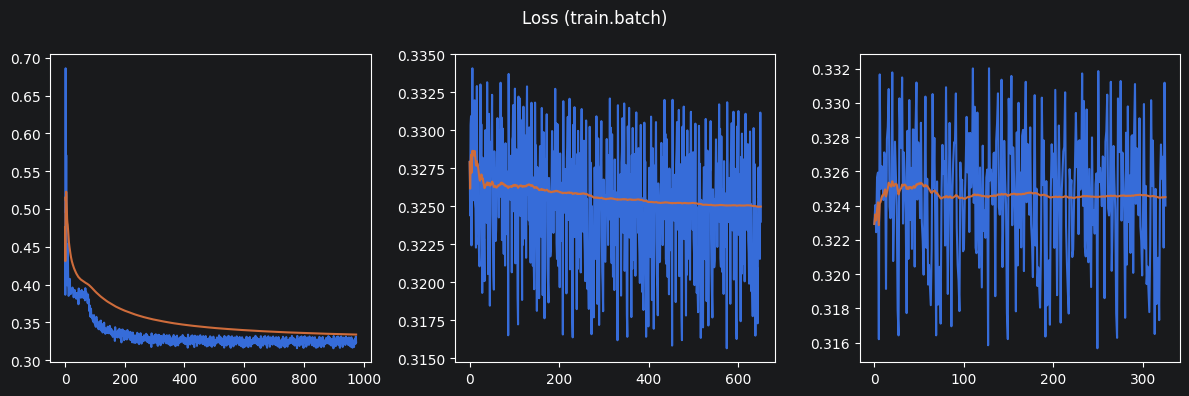

In [27]:
try:
    pre_trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

In [28]:
try:
    # pre_trainer.loss['train.batch'] = pre_trainer.loss['train.batch'][1500:]
    print(len(pre_trainer.loss['train.batch']))
except:
    traceback.print_exc()

976


In [29]:
try:
    for key in pre_trainer.timer.timers:
        print(key, pre_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 449.13042634999874
_train_step 112.2453012875003
train_dataloader 0.815101195901613
batch 0.10435142684431054


In [30]:
try:
    pre_trainer.save_model("pretrained_feature_embedder_v3_128_t1")
except:
    traceback.print_exc()

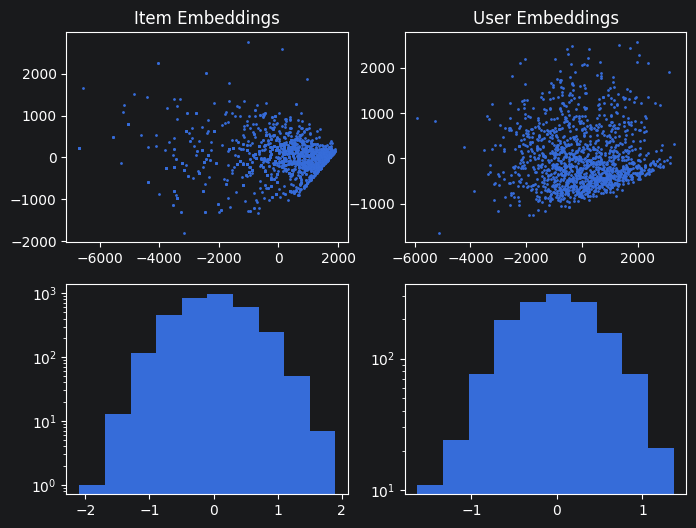

In [31]:
try:
    pass
    plot_tsne_pca_stuff(False)
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [32]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    n_dif = 0
    with torch.no_grad():
        model.prepare_for_feature_based_embeds_training()
        model.eval()
        model.to('cpu')
        temp_ds = DataLoader(vvic, batch_size=8192)
        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            # pos_score, neg_scores = torch.sigmoid(pos_score).numpy(), [torch.sigmoid(x).numpy() for x in neg_scores]
            pos_score, neg_scores = (pos_score).numpy(), [(x).numpy() for x in neg_scores]

            n_pos = n_pos + (pos_score > 0.0).sum()
            n_neg = n_neg + sum([(x < 0.0).sum() for x in neg_scores])
            n_dif = n_dif + (pos_score > neg_scores).sum()

            # n_pos = n_pos + (pos_score > neg_scores).sum()
            # n_neg = n_neg + (pos_score < neg_scores).sum()
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))

    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))
    print("DIFF SCORES")
    print("Diff    : ", n_dif)

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:16<00:00,  1.60s/it]

POS SCORES
Accuracy:  0.01444745015529506
Avg Weig:  -0.11170926
NEG SCORES
Accuracy:  0.460039074241058
Avg Weig:  -0.24587807
DIFF SCORES
Diff    :  348330


In [34]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
    print("DIFF SCORES")
    print("Diff    : ", n_dif / 81920 / 6)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.176025390625
NEG SCORES
Accuracy:  0.934173583984375
DIFF SCORES
Diff    :  0.70867919921875


## Training the model with focus only on item based embeddings

Allowing it to learn the the item based embeddings (and bias) to close the gap

In [35]:
try:
    id_training_loss = locals().get('id_training_loss', None)
    id_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.01),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=id_training_loss,
    )
    id_training_loss = id_trainer.loss
    # id_trainer.load_model("model_id_trained_embedder_v3_128.pt")
except:
    traceback.print_exc()

In [40]:
try:
    pass
    # id_trainer.load_model("model_id_trained_embedder_v3.pt")
    id_trainer.epochs = 4
    # id_trainer.model_criteria_step = model_criteria_step
    # id_trainer.model_criteria_step = model_criteria_step_ranking
    id_trainer.model_criteria_step = model_criteria_step_trun_1
    id_trainer.device = 'cuda'
    # id_trainer.train_dataloader = DataLoader(vvic, batch_size=8192)
    # id_trainer.learning_rate(0.01)
except:
    traceback.print_exc()

In [46]:
try:
    model.prepare_for_id_based_embeds_training()
    id_trainer.train()
except:
    traceback.print_exc()

C:\Users\mcxiv\AppData\Local\Temp\ipykernel_17564\1063010763.py:31: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([8192])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(preds, torch.log1p(truth) - median)


Epoch:  0/ 4    Train Loss: 0.25    TTS: 1.04    ETA: 508.81
Epoch:  0/ 4    Train Loss: 0.26    TTS: 2.83    ETA: 457.43
Epoch:  0/ 4    Train Loss: 0.26    TTS: 3.81    ETA: 461.48
Epoch:  0/ 4    Train Loss: 0.25    TTS: 4.85    ETA: 468.35
Epoch:  0/ 4    Train Loss: 0.25    TTS: 5.82    ETA: 467.72
Epoch:  0/ 4    Train Loss: 0.26    TTS: 6.75    ETA: 463.73
Epoch:  0/ 4    Train Loss: 0.26    TTS: 7.68    ETA: 460.79
Epoch:  0/ 4    Train Loss: 0.26    TTS: 8.53    ETA: 453.74
Epoch:  0/ 4    Train Loss: 0.26    TTS: 9.44    ETA: 451.38
Epoch:  0/ 4    Train Loss: 0.25    TTS: 10.32    ETA: 447.41
Epoch:  0/ 4    Train Loss: 0.25    TTS: 11.24    ETA: 445.77
Epoch:  0/ 4    Train Loss: 0.25    TTS: 12.18    ETA: 444.94
Epoch:  0/ 4    Train Loss: 0.25    TTS: 13.09    ETA: 443.29
Epoch:  0/ 4    Train Loss: 0.26    TTS: 14.02    ETA: 442.24
Epoch:  0/ 4    Train Loss: 0.25    TTS: 15.99    ETA: 442.99
Epoch:  0/ 4    Train Loss: 0.25    TTS: 16.92    ETA: 441.89
Epoch:  0/ 4    T

C:\Users\mcxiv\AppData\Local\Temp\ipykernel_17564\1063010763.py:31: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([6868])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(preds, torch.log1p(truth) - median)


Epoch:  1/ 4    Train Loss: 0.25    Agg. Loss: 0.25    TTS: 113.03    ETA: 339.09
Epoch:  1/ 4    Train Loss: 0.25    TTS: 113.03
Epoch:  1/ 4    Train Loss: 0.26    TTS: 114.85    ETA: 337.15
Epoch:  1/ 4    Train Loss: 0.26    TTS: 115.78    ETA: 336.23
Epoch:  1/ 4    Train Loss: 0.26    TTS: 116.62    ETA: 335.05
Epoch:  1/ 4    Train Loss: 0.25    TTS: 117.62    ETA: 334.34
Epoch:  1/ 4    Train Loss: 0.25    TTS: 118.45    ETA: 333.13
Epoch:  1/ 4    Train Loss: 0.26    TTS: 119.38    ETA: 332.24
Epoch:  1/ 4    Train Loss: 0.26    TTS: 120.37    ETA: 331.48
Epoch:  1/ 4    Train Loss: 0.26    TTS: 121.28    ETA: 330.50
Epoch:  1/ 4    Train Loss: 0.26    TTS: 122.27    ETA: 329.75
Epoch:  1/ 4    Train Loss: 0.25    TTS: 123.11    ETA: 328.60
Epoch:  1/ 4    Train Loss: 0.25    TTS: 124.99    ETA: 326.83
Epoch:  1/ 4    Train Loss: 0.25    TTS: 125.88    ETA: 325.80
Epoch:  1/ 4    Train Loss: 0.26    TTS: 126.82    ETA: 324.92
Epoch:  1/ 4    Train Loss: 0.25    TTS: 127.65    

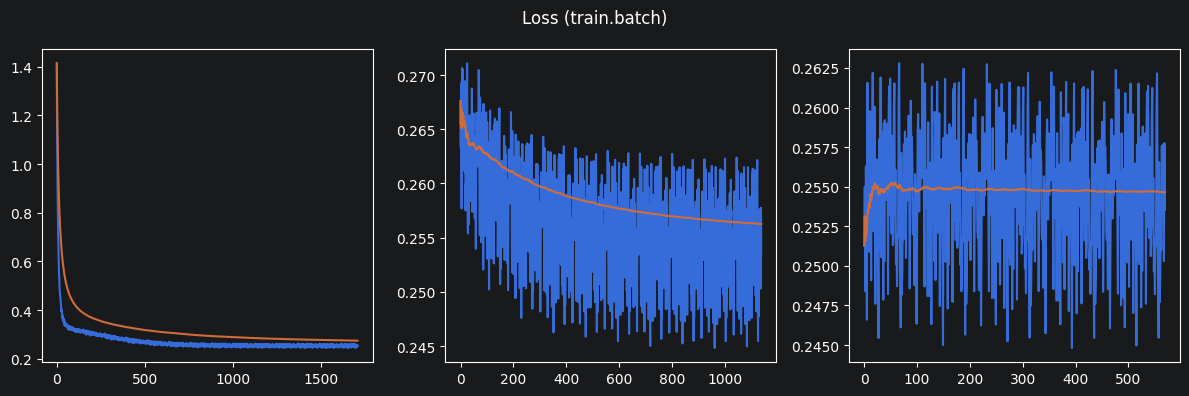

In [47]:
try:
    id_trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

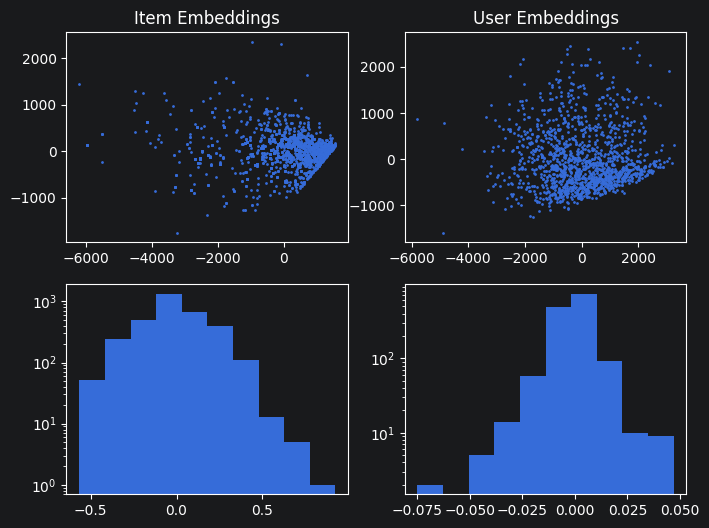

In [48]:
try:
    plot_tsne_pca_stuff(True)
except:
    traceback.print_exc()

In [49]:
try:
    # id_trainer.loss['train.batch'] = id_trainer.loss['train.batch'][3000:]
    print(len(id_trainer.loss['train.batch']))
except:
    traceback.print_exc()

1708


In [50]:
try:
    for key in id_trainer.timer.timers:
        print(key, id_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 392.61494349999975
_train_step 112.13850628571397
train_dataloader 0.8080272166862259
batch 0.11072787037474549


In [63]:
try:
    id_trainer.save_model("id_trained_embedder_v3_128")
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [52]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    n_dif = 0
    diffs = 0
    with torch.no_grad():
        model.prepare_for_id_based_embeds_training()
        model.eval()
        d = torch.device('cpu')
        model.to(d)
        temp_ds = DataLoader(vvic, batch_size=8192)

        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            (uid, uft, pii, pif, nid), (pir, nirs) = tree_map(lambda x: x.to(d), ((uid, uft, pii, pif, nid), (pir, nirs)))
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            pos_score, neg_scores = pos_score.cpu().numpy(), [x.cpu().numpy() for x in neg_scores]
            n_pos = n_pos + (pos_score > 0.5).sum()
            n_neg = n_neg + sum([(x < 0.5).sum() for x in neg_scores])
            n_dif = n_dif + (pos_score > neg_scores).sum()
            diffs += (pos_score - neg_scores).mean()
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))
    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))
    print("DIFF SCORES")
    print("Diff    : ", n_dif)

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:15<00:00,  1.58s/it]

POS SCORES
Accuracy:  0.0006281935677787797
Avg Weig:  -0.037493203
NEG SCORES
Accuracy:  0.4921540927762749
Avg Weig:  -0.3212434
DIFF SCORES
Diff    :  405437


In [53]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
    print("DIFF SCORES")
    print("Diff    : ", n_dif / 81920 / 6)
    print("Diff    : ", diffs / 10)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.00765380859375
NEG SCORES
Accuracy:  0.9993876139322917
DIFF SCORES
Diff    :  0.8248636881510416
Diff    :  0.28375024


## Hmmm...

In [57]:
try:
    with torch.no_grad():
        model.eval()
        idx = random.randint(1, 1000)
        print(idx)  # 121
        (uid, uft, pii, pif, nid), (pir, nirs) = vvic[143]
        nid, nif = nid[0]
        nir = nirs[0]
        # (uid, uft, pii, pif, nid, nif), (pr, nr) = vvic[idx]
        uid, uft, pii, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pii], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        print("User ID:", uid)
        print("Pos  ID:", pii)
        print("Neg  ID:", nid)
        uem, _ = user_model(uid, uft, use_bias=False)
        pie, _ = item_model(pii, pif, use_bias=False)
        nie, _ = item_model(nid, nif, use_bias=False)
        print("Feat Only Dot Pos:", (uem * pie).sum(dim=1))
        print("Feat Only Dot Neg:", (uem * nie).sum(dim=1))
        uem, ubs = user_model(uid, uft, use_bias=True)
        pie, pib = item_model(pii, pif, use_bias=True)
        nie, nib = item_model(nid, nif, use_bias=True)
        print("With ID   Dot Pos:", (uem * pie).sum(dim=1) + ubs + pib)
        print("With ID   Dot Neg:", (uem * nie).sum(dim=1) + ubs + nib)
        model.prepare_for_feature_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model FO      Pos:", pos)
        print("Model FO      Neg:", neg)
        model.prepare_for_id_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model WB      Pos:", pos)
        print("Model WB      Neg:", neg)
        print("Ground Truth  Pos:", pir - np.log1p(0.8))
        print("Ground Truth  Neg:", nir - np.log1p(0.8))
except:
    traceback.print_exc()

794
User ID: tensor([6018])
Pos  ID: tensor([10019])
Neg  ID: tensor([6898])
Feat Only Dot Pos: tensor([-556346.5000])
Feat Only Dot Neg: tensor([-2093532.5000])
With ID   Dot Pos: tensor([-443262.])
With ID   Dot Neg: tensor([-1727401.5000])
Model FO      Pos: tensor([-0.0719])
Model FO      Neg: tensor([-772.6472])
Model WB      Pos: tensor([-0.0717])
Model WB      Neg: tensor([-641.6298])
Ground Truth  Pos: 0.4180301523815113
Ground Truth  Neg: -0.05198656552925529


In [59]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        uid = data_model.ratings['user_id'].sample(1).iloc[0]
        print("User ID", uid)
        subset = data_model.ratings[data_model.ratings['user_id'] == uid]
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor([uid]), torch.tensor(uft)
        uem, ubs = user_model(uid, uft)

        iid = subset['item_id'].values
        ift = data_model.get_item_features(iid)
        iid, ift = torch.tensor(iid), torch.tensor(ift)
        iem, ibs = item_model(iid, ift)

        grt = subset['rating'].values

        uem = F.normalize(uem, dim=1)
        iem = F.normalize(iem, dim=1)
        prt = (uem * iem).sum(dim=1)
        print(prt.shape)
        print(prt.mean(), prt.min(), prt.max(), prt.std())

        for g, p in zip(grt, prt):
            print(g, p.item())

        # results = []
        #
        # for sample in subset.itertuples():
        #     iid = sample.item_id
        #     ift = data_model.get_item_features(iid)
        #     iid, ift = torch.tensor([iid]), torch.tensor(ift)
        #
        #     results.append((sample.rating, model(uid, uft, pii, pif)[0].item()))
        #     print(sample.rating, ",", model(uid, uft, pii, ift)[0].item(), ",", model(None, uft, None, ift)[0].item())

except:
    traceback.print_exc()

User ID 1500
torch.Size([708])
tensor(-0.2132) tensor(-0.5937) tensor(0.2652) tensor(0.1733)
0.5292093187433816 -0.16055651009082794
0.1403838301347488 -0.45104309916496277
1.0272176417999404 0.010658785700798035
0.9163718692514504 0.08011502027511597
0.2166464052472364 -0.5857994556427002
2.2046575883165582 0.04125828668475151
0.7864163121607746 -0.09765911102294922
0.7057863687711812 -0.13785387575626373
2.095800270950261 0.2652238607406616
1.1335950511539377 -0.001655079424381256
0.8281778919108206 -0.12041427195072174
0.5097360877730552 -0.35118967294692993
0.2539132379248658 -0.36127620935440063
1.1637588001224364 -0.18499036133289337
0.4760004201239365 -0.04844540357589722
1.35 -0.22351595759391785
1.379539415411869 -0.04369768872857094
0.6020380434782608 -0.10661030560731888
0.2699910598986788 -0.45514488220214844
0.7291549295774647 -0.1492815762758255
4.189016393442623 -0.04798629879951477
1.2583937287383524 0.042818792164325714
0.1670642201834862 -0.2883428633213043
0.82920652

In [60]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        iid = data_model.ratings['item_id'].sample(100).values
        ift = data_model.get_item_features(iid)
        iid, ift = torch.tensor(iid), torch.tensor(ift)

        iem, ibs = item_model(iid, ift)
        print(iem.std(dim=0).mean())

        uid = data_model.ratings['user_id'].sample(100).values
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor(uid), torch.tensor(uft)

        uem, ubs = user_model(uid, uft)
        print(uem.std(dim=0).mean())
        print(uem.norm(dim=-1).mean())
except:
    traceback.print_exc()

tensor(120.4493)
tensor(120.1652)
tensor(5139.5864)


In [61]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        uid = data_model.ratings['user_id'].sample(1).iloc[0]
        print("User ID", uid)
        subset = data_model.ratings[data_model.ratings['user_id'] == uid]
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor([uid]), torch.tensor(uft)

        print(user_model(None, uft)[0].shape)

except:
    traceback.print_exc()

User ID 7133
torch.Size([1, 128])


# Oi?

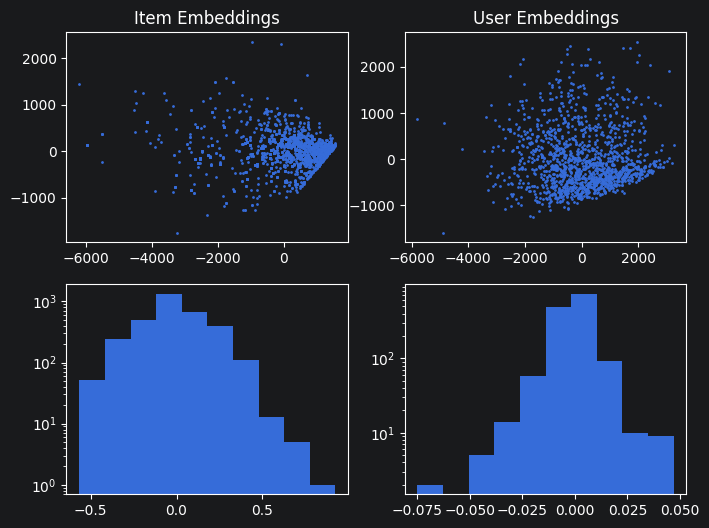

In [62]:
try:
    plot_tsne_pca_stuff()
except:
    traceback.print_exc()